Dataset Loaded Successfully!
                                       text_combined  label
0  hpl nom may 25 2001 see attached file hplno 52...      0
1  nom actual vols 24 th forwarded sabrae zajac h...      0
2  enron actuals march 30 april 1 201 estimated a...      0
3  hpl nom may 30 2001 see attached file hplno 53...      0
4  hpl nom june 1 2001 see attached file hplno 60...      0

Model Training Completed!

Model Accuracy: 96.95 %

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.95      0.99      0.97      7919
        Spam       0.99      0.95      0.97      8579

    accuracy                           0.97     16498
   macro avg       0.97      0.97      0.97     16498
weighted avg       0.97      0.97      0.97     16498



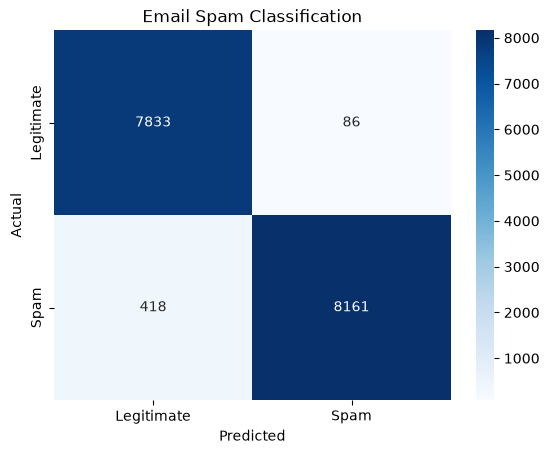


New Email Classification: SPAM


In [1]:
# Email Spam Classification Using Naive Bayes

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.pipeline import Pipeline

# Step 1: Load Dataset
df = pd.read_csv("phishing_email.csv")

print("Dataset Loaded Successfully!")
print(df.head())

# Step 2: Check and clean data
df = df.dropna(subset=['text_combined', 'label'])

df['text_combined'] = df['text_combined'].astype(str)
df['label'] = pd.to_numeric(df['label'], errors='coerce')

df = df.dropna(subset=['label'])
df = df[df['label'].isin([0, 1])]
df['label'] = df['label'].astype(int)

# Step 3: Separate features and target
X = df['text_combined']
y = df['label']

# Step 4: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Step 5: Create Naive Bayes model
model = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=30000,
        stop_words='english',
        ngram_range=(1, 2)
    )),
    ('classifier', MultinomialNB())
])

# Step 6: Train model
model.fit(X_train, y_train)

print("\nModel Training Completed!")

# Step 7: Predict test data
y_pred = model.predict(X_test)

# Step 8: Evaluate model
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Legitimate', 'Spam']
))

# Step 9: Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Legitimate', 'Spam'],
    yticklabels=['Legitimate', 'Spam']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Email Spam Classification")
plt.show()

# Step 10: Test a new email
new_email = [
    "Congratulations! You have won a free prize. Click here to claim now."
]

prediction = model.predict(new_email)

if prediction[0] == 1:
    print("\nNew Email Classification: SPAM")
else:
    print("\nNew Email Classification: LEGITIMATE")